# Descriptive Statistics

Companion notebook for the note [Descriptive Statistics](../../notes/foundations/descriptive_statistics.md).

We build frequency tables, compute measures of center and spread, compare mean and median on skewed data, and look at quartiles and boxplots. Everything uses `numpy`, `scipy`, and `matplotlib` with a fixed random seed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)

## 1. Frequency, relative frequency, cumulative relative frequency

The sibling-count dataset from the note has 10 observations. The frequency of a value is its count, the relative frequency divides by $n$, and the cumulative relative frequency is the running sum (meaningful here because the values are ordered).

value  freq  rel   cum
    0     2   20%   20%
    1     3   30%   50%
    2     3   30%   80%
    3     1   10%   90%
    4     1   10%  100%


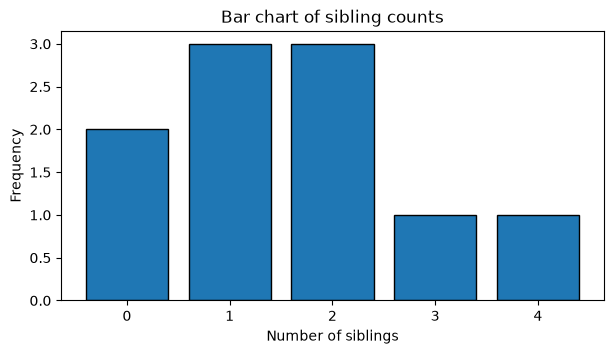

In [2]:
siblings = np.array([2, 0, 1, 3, 1, 2, 0, 4, 1, 2])
values, freq = np.unique(siblings, return_counts=True)
rel = freq / freq.sum()
cum = np.cumsum(rel)

print("value  freq  rel   cum")
for v, f, r, c in zip(values, freq, rel, cum):
    print(f"{v:5d} {f:5d} {r:5.0%} {c:5.0%}")

fig, ax = plt.subplots()
ax.bar(values, freq, edgecolor="black")
ax.set_xlabel("Number of siblings"); ax.set_ylabel("Frequency")
ax.set_title("Bar chart of sibling counts")
plt.show()

## 2. Grouping continuous data into half-open bins

Heights are continuous, so we count observations in half-open intervals $[165,168),[168,171),\ldots$ as in the note. A value exactly on a boundary belongs to the interval that starts there.

[165, 168): 3
[168, 171): 3
[171, 174): 3
[174, 177): 1
total: 10


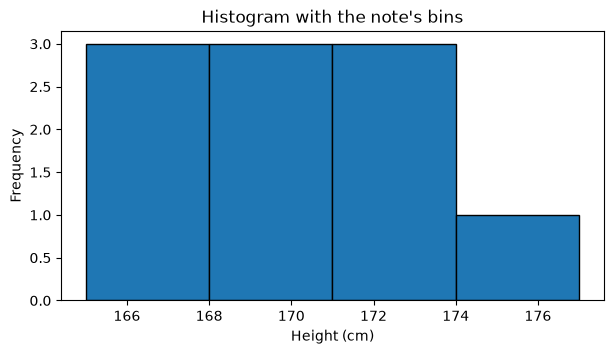

In [3]:
heights = np.array([170.2, 165.5, 172.3, 168.7, 171.6, 167.4, 169.5, 174.2, 166.1, 173.5])
edges = [165, 168, 171, 174, 177]
counts, _ = np.histogram(heights, bins=edges)
for lo, hi, c in zip(edges[:-1], edges[1:], counts):
    print(f"[{lo}, {hi}): {c}")
print("total:", counts.sum())

plt.hist(heights, bins=edges, edgecolor="black")
plt.xlabel("Height (cm)"); plt.ylabel("Frequency"); plt.title("Histogram with the note's bins")
plt.show()

## 3. Measures of center

For the weekly sales data (17, 21, 17, 35, 23, 14, 24) the note finds mean $=151/7\approx21.57$, median $=21$, mode $=17$. The weighted and geometric means follow the formulas

$$\bar{x}_w=\frac{\sum w_i x_i}{\sum w_i},\qquad G=\left(\prod x_i\right)^{1/n}.$$

In [4]:
sales = np.array([17, 21, 17, 35, 23, 14, 24])
print("mean   :", round(sales.mean(), 2))
print("median :", np.median(sales))
print("mode   :", stats.mode(sales, keepdims=False).mode)

# Weighted mean (course grade) and geometric mean (growth factors)
print("weighted mean:", np.average([80, 90, 70], weights=[0.5, 0.3, 0.2]))
factors = np.array([1.10, 0.95, 1.20])
print("geometric mean:", round(stats.gmean(factors), 4), "vs arithmetic:", round(factors.mean(), 4))

mean   : 21.57
median : 21.0
mode   : 17
weighted mean: 81.0
geometric mean: 1.0784 vs arithmetic: 1.0833


## 4. Mean versus median on skewed data

The mean uses every value, so one extreme observation moves it a lot. The median depends only on the ordering. We add a single huge value to a simulated, roughly symmetric sample and watch both summaries.

In [5]:
base = rng.normal(loc=50, scale=5, size=99)
with_outlier = np.append(base, 500.0)

for label, x in [("without outlier", base), ("with one outlier", with_outlier)]:
    print(f"{label:17s} mean={x.mean():7.2f} median={np.median(x):6.2f} "
          f"sd={x.std(ddof=1):7.2f} IQR={stats.iqr(x):5.2f}")

without outlier   mean=  49.79 median= 50.06 sd=   3.88 IQR= 5.15
with one outlier  mean=  54.29 median= 50.20 sd=  45.19 IQR= 5.17


The mean and standard deviation jump while the median and IQR barely change: the median and IQR are *resistant*, the mean and SD are not.

## 5. Variance: population versus sample

The population variance divides by $N$; the sample variance divides by $n-1$. With $n=7$ sales values the two differ noticeably (note: 41.10 versus 47.95), and the gap shrinks as $n$ grows.

In [6]:
print("population variance:", round(sales.var(ddof=0), 2), " sd:", round(sales.std(ddof=0), 2))
print("sample variance     :", round(sales.var(ddof=1), 2), " sd:", round(sales.std(ddof=1), 2))

# Unbiasedness: average s^2 over many samples of size 5 from a population with sigma^2 = 4
samples = rng.normal(0, 2, size=(20000, 5))
print("mean of ddof=0 estimates:", round(samples.var(axis=1, ddof=0).mean(), 3))
print("mean of ddof=1 estimates:", round(samples.var(axis=1, ddof=1).mean(), 3), "(true value 4)")

population variance: 41.1  sd: 6.41
sample variance     : 47.95  sd: 6.92
mean of ddof=0 estimates: 3.227
mean of ddof=1 estimates: 4.034 (true value 4)


## 6. Percentiles, quartiles, and the $1.5\,\mathrm{IQR}$ rule

`numpy.percentile` with its default linear interpolation uses the position $r=1+(n-1)P/100$ from the note. For the exam scores 15, 20, 22, 24, 30, 35, 40 we get $Q_1=21$, $Q_2=24$, $Q_3=32.5$.

P30 = 21.6
Q1, Q2, Q3 = 21.0 24.0 32.5  IQR = 11.5
fences: 3.75 49.75 -> outliers: []


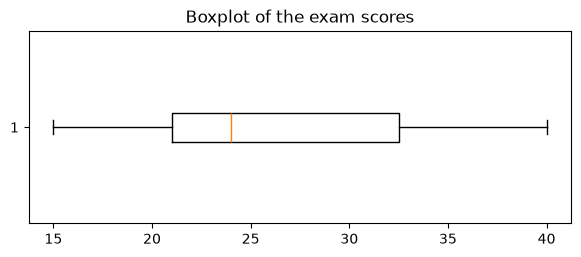

In [7]:
scores = np.array([40, 30, 15, 24, 20, 22, 35])
q1, q2, q3 = np.percentile(scores, [25, 50, 75])
iqr = q3 - q1
print("P30 =", np.percentile(scores, 30))
print("Q1, Q2, Q3 =", q1, q2, q3, " IQR =", iqr)
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("fences:", lo, hi, "-> outliers:", scores[(scores < lo) | (scores > hi)])

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.boxplot(scores, orientation="horizontal")
ax.set_title("Boxplot of the exam scores")
plt.show()

## 7. Standardizing to compare across scales

A $z$-score $z=(x-\mu)/\sigma$ measures how many standard deviations an observation is from the mean, putting different scales on a common footing. Chloe's 100 m time (53 s; $\mu=60$, $\sigma=4$) and Liam's marathon (175 min; $\mu=240$, $\sigma=30$) are compared this way in the note.

In [8]:
z_chloe = (53 - 60) / 4
z_liam = (175 - 240) / 30
print(f"Chloe z = {z_chloe:.2f}, Liam z = {z_liam:.2f}")
print("Both are below the mean (faster); Liam's result is further from average.")

Chloe z = -1.75, Liam z = -2.17
Both are below the mean (faster); Liam's result is further from average.
